In [48]:
%load_ext autoreload
%autoreload 2

import numpy as np 
import pandas as pd
from credit_risk_ai.data.load import load_train
from credit_risk_ai.data.clean import clean, drop_duplicate_rows

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    average_precision_score,
    brier_score_loss,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

TARGET = "SeriousDlqin2yrs"
RANDOM_STATE = 42
VAL_SIZE = 0.2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [49]:
data = clean(drop_duplicate_rows(load_train()))

X = data.drop(columns=[TARGET])
y = data[TARGET]

print(data.shape, X.shape, round(y.mean(), 3))
# expected: (149391, 15) (149391, 14) 0.067

(149391, 15) (149391, 14) 0.067


In [50]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=VAL_SIZE, stratify=y, random_state=RANDOM_STATE)

print(len(X_train), len(X_val)) #119512 29879
print(round(y_train.mean(), 3), round(y_val.mean(), 3))
print(len(X_train.index.intersection(X_val.index)))


119512 29879
0.067 0.067
0


In [51]:
def evaluate(name, model, X_val, y_val):
    """Score a fitted model on the validation set.

    All three metrics use probabilities, so none of them depends on a threshold:
      - roc_auc: how well defaulters are ranked above non-defaulters (higher is better)
      - pr_auc:  how well defaulters are found on imbalanced data (higher is better)
      - brier:   how accurate the predicted probabilities are (lower is better)
    """
    proba = model.predict_proba(X_val)[:, 1]
    return {
        "model": name,
        "roc_auc": roc_auc_score(y_val, proba),
        "pr_auc": average_precision_score(y_val, proba),
        "brier": brier_score_loss(y_val, proba),
    }

result = []

In [52]:
dummy = DummyClassifier(strategy='prior')
dummy.fit(X_train, y_train)

result.append(evaluate("dummy", dummy, X_val, y_val))
print(result[-1])

{'model': 'dummy', 'roc_auc': 0.5, 'pr_auc': 0.06700358111047894, 'brier': 0.06251410126636343}


## Step 5: LogisticRegression in a Pipeline

The pipeline has four steps, run in this order:

1. **`impute`:** fill missing values (NaN) with the median. LogisticRegression cannot handle NaN.
2. **`log`:** `log1p` pulls in the long tails (income goes up to about 3 million).
3. **`scale`:** `StandardScaler` puts every column on the same scale. It must come **after** `log`: scaling creates negative values, some below −1, and `log1p` of a value below −1 is NaN.
4. **`model`:** `LogisticRegression`.

`fit` runs on `X_train` only: the pipeline learns the medians, means/stds and model coefficients from the training data. When scoring, `predict_proba(X_val)` only *applies* what was learned. This is the golden rule (learning note 2.9).

In [53]:
log_reg = Pipeline([
    ("impute", SimpleImputer(strategy="median")),                            # 1. fill NaN with the median
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),  # 2. pull in long tails
    ("scale", StandardScaler()),                                             # 3. put columns on one scale
    ("model", LogisticRegression(max_iter=1000)),                            # 4. the model
])

log_reg.fit(X_train, y_train)  # learns every step, from the training data only

result.append(evaluate("logistic_regression", log_reg, X_val, y_val))
print(result[-1])
print("Iterations to converge:", log_reg.named_steps["model"].n_iter_[0])
# expected: roc_auc ≈ 0.855, far fewer than 1000 iterations

{'model': 'logistic_regression', 'roc_auc': 0.8548123953386355, 'pr_auc': 0.38811746603599434, 'brier': 0.050217809692730014}
Iterations to converge: 12


In [54]:
# Leakage check: the medians the pipeline learned must be the medians of X_train,
# not of the full X. The table shows only the columns where those two medians differ.
learned = pd.Series(log_reg.named_steps["impute"].statistics_, index=X_train.columns)
medians = pd.DataFrame({
    "learned by pipeline": learned,
    "X_train median": X_train.median(),
    "full X median": X.median(),
})

print("Matches X_train:", np.allclose(learned, X_train.median()))
print("Matches full X: ", np.allclose(learned, X.median()))
medians[medians["X_train median"] != medians["full X median"]]
# expected: True, False. MonthlyIncome learned 5500 (train), not 5483 (full X)

Matches X_train: True
Matches full X:  False


,learned by pipeline,X_train median,full X median
RevolvingUtilizationOfUnsecuredLines,0.152934,0.152934,0.153564
DebtRatio,0.290462,0.290462,0.291363
MonthlyIncome,5500.000000,5500.000000,5483.000000


In [55]:
hist = HistGradientBoostingClassifier(random_state=RANDOM_STATE)

hist.fit(X_train, y_train)
result.append(evaluate("hist_gradient_boosting", hist, X_val, y_val))
print(result[-1])


{'model': 'hist_gradient_boosting', 'roc_auc': 0.8624918862749331, 'pr_auc': 0.3950674731681976, 'brier': 0.049136862726045484}


In [56]:
import matplotlib.pyplot as plt

comparision = pd.DataFrame(result).sort_values("roc_auc", ascending=False)
comparision


,model,roc_auc,pr_auc,brier
2,hist_gradient_boosting,0.862492,0.395067,0.049137
1,logistic_regression,0.854812,0.388117,0.050218
0,dummy,0.500000,0.067004,0.062514


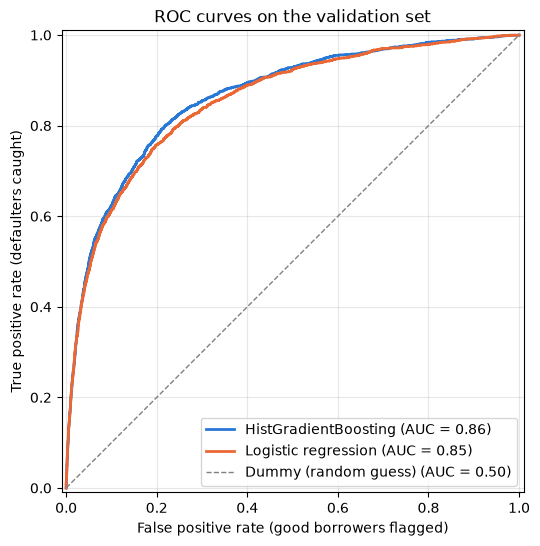

In [57]:
models = {
    "HistGradientBoosting": (hist, {"color": "#2a78d6", "linewidth": 2}),
    "Logistic regression": (log_reg, {"color": "#eb6834", "linewidth": 2}),
    "Dummy (random guess)": (dummy, {"color": "gray", "linewidth": 1, "linestyle": "--"})


}

fig, ax = plt.subplots(figsize= (6, 6))
for name, (model, style) in models.items():
    #Call predict_proba on X_Val and draws the curve:
    RocCurveDisplay.from_estimator(model, X_val, y_val, name=name, ax=ax, curve_kwargs=style)

ax.set_title("ROC curves on the validation set")
ax.set_xlabel("False positive rate (good borrowers flagged)")
ax.set_ylabel("True positive rate (defaulters caught)")
ax.grid(alpha=0.3)
ax.legend(loc='lower right')
plt.show()

## Step 8: Conclusions

**Results on the validation set** (29,879 borrowers, 6.7% defaults):

| Model | ROC-AUC (higher is better) | PR-AUC (higher is better) | Brier (lower is better) |
|---|---|---|---|
| HistGradientBoosting | **0.862** | **0.395** | **0.049** |
| Logistic regression (impute → log1p → scale) | 0.855 | 0.388 | 0.050 |
| Dummy (random guess) | 0.500 | 0.067 | 0.063 |

**What the results show**

- Both real models are far better than random guessing: ROC-AUC 0.86 against 0.50, and a PR-AUC about 6 times the default rate.
- HistGradientBoosting is the best model, but only by 0.008 ROC-AUC over logistic regression. Their ROC curves almost overlap: when 20% of good borrowers are flagged, it catches about 80% of defaulters against about 77%.
- HistGradientBoosting also has the lowest Brier score: 0.049, about 21% lower than always predicting the 6.7% default rate (0.063).
- HistGradientBoosting needs no imputation or scaling: it handles NaN itself, and trees are not affected by feature scale. Logistic regression needs the full pipeline, and with `log1p` + scaling it converges in 12 iterations.
- The leakage check confirms that the pipeline learned its medians from `X_train` only.

**Limitations**

- All scores come from a single 80/20 split. A gap of 0.008 may partly depend on which rows ended up in the validation set.
- Nothing is tuned yet: HistGradientBoosting uses its default parameters.
- The Brier score shows the probabilities are better than the base rate overall, but they have not been checked for calibration yet (whether "20%" really means 20% of those borrowers default).
- Precision, recall and F1 depend on a threshold; they are analysed in step 9.

**Next steps**

1. Replace the single split with stratified 5-fold cross-validation, to get an average score and its spread for each model.
2. Feature engineering, e.g. the total number of late payments, or income per family member.
3. Tune HistGradientBoosting with `RandomizedSearchCV` inside cross-validation.
4. Check and calibrate the predicted probabilities (calibration curve, `CalibratedClassifierCV`).
5. Move the chosen pipeline into `src/credit_risk_ai/models/` with tests, then train it on all the training data and create the Kaggle submission.

## Step 9: Threshold analysis

ROC-AUC, PR-AUC and Brier score use probabilities directly. Precision, recall, F1 and the confusion matrix need a **threshold** first: a borrower is flagged as risky when the predicted probability is at least the threshold.

- `predict()` silently uses a threshold of **0.5**. With only 6.7% defaulters, very few borrowers get a probability that high, so the model looks much worse than it is.
- Lowering the threshold catches more defaulters (higher **recall**) but also flags more good borrowers, so a smaller share of flagged borrowers really default (lower **precision**).
- **F1** weighs precision and recall equally. In credit risk, a missed defaulter (lost principal) usually costs more than a rejected good borrower (lost interest), so the final threshold should come from business costs. The max-F1 threshold is only a neutral starting point.
- The threshold is chosen on the **validation set only**, then kept fixed. Never tune it on the test set.

The analysis below uses the best model from step 7, HistGradientBoosting.

In [58]:
# Step 9a: precision, recall and F1 of the best model at several thresholds
best_model = hist
proba_val = best_model.predict_proba(X_val)[:, 1]

rows = []
for threshold in [0.5, 0.4, 0.3, 0.2, 0.1, 0.05]:
    flagged = (proba_val >= threshold).astype(int)  # 1 = flagged as risky
    rows.append({
        "threshold": threshold,
        "flagged_share": flagged.mean(),  # share of all borrowers that get flagged
        "precision": precision_score(y_val, flagged, zero_division=0),
        "recall": recall_score(y_val, flagged),
        "f1": f1_score(y_val, flagged),
    })

threshold_table = pd.DataFrame(rows).round(3)
threshold_table

,threshold,flagged_share,precision,recall,f1
0,0.50,0.022,0.578,0.188,0.284
1,0.40,0.038,0.518,0.294,0.375
2,0.30,0.062,0.456,0.419,0.436
3,0.20,0.091,0.391,0.532,0.451
4,0.10,0.175,0.264,0.691,0.382
5,0.05,0.308,0.183,0.839,0.300


Max-F1 threshold: 0.218 -> precision 0.409, recall 0.515, F1 0.456


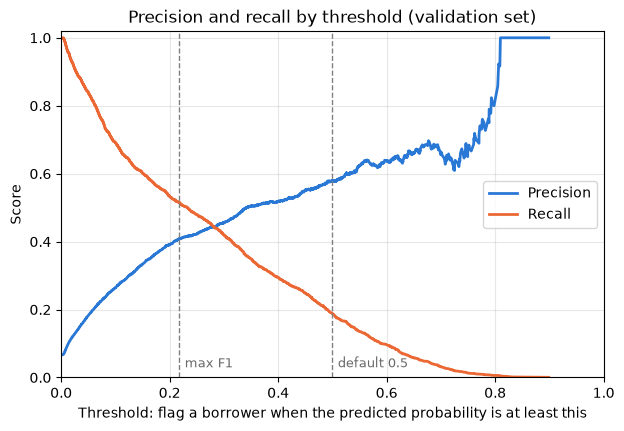

In [59]:
# Step 9b: precision and recall at every possible threshold, and the threshold with the best F1
precision, recall, thresholds = precision_recall_curve(y_val, proba_val)
precision, recall = precision[:-1], recall[:-1]  # the last point has no matching threshold

with np.errstate(divide="ignore", invalid="ignore"):
    f1 = 2 * precision * recall / (precision + recall)
best = np.nanargmax(f1)
f1_threshold = thresholds[best]
print(f"Max-F1 threshold: {f1_threshold:.3f} -> precision {precision[best]:.3f}, "
      f"recall {recall[best]:.3f}, F1 {f1[best]:.3f}")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(thresholds, precision, color="#2a78d6", linewidth=2, label="Precision")
ax.plot(thresholds, recall, color="#eb6834", linewidth=2, label="Recall")
for x, text in [(0.5, "default 0.5"), (f1_threshold, "max F1")]:
    ax.axvline(x, color="gray", linestyle="--", linewidth=1)
    ax.text(x + 0.01, 0.03, text, color="dimgray", fontsize=9)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_title("Precision and recall by threshold (validation set)")
ax.set_xlabel("Threshold: flag a borrower when the predicted probability is at least this")
ax.set_ylabel("Score")
ax.grid(alpha=0.3)
ax.legend(loc="center right")
plt.show()

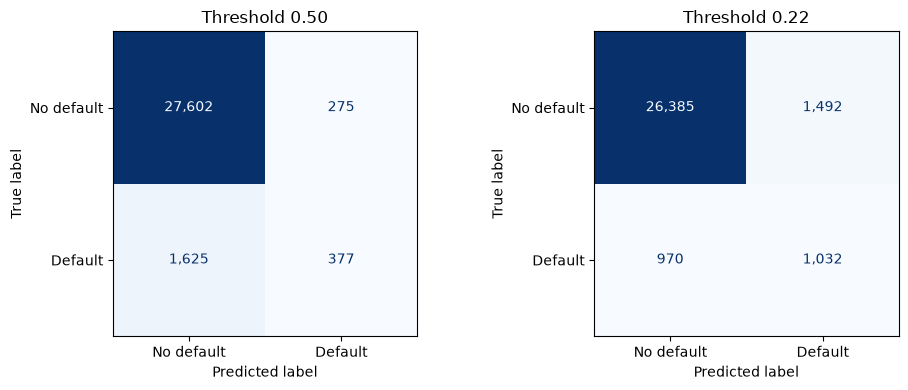

In [60]:
# Step 9c: confusion matrices at the default threshold and at the max-F1 threshold
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, threshold in zip(axes, [0.5, f1_threshold]):
    ConfusionMatrixDisplay.from_predictions(
        y_val,
        (proba_val >= threshold).astype(int),
        display_labels=["No default", "Default"],
        values_format=",",
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(f"Threshold {threshold:.2f}")
plt.tight_layout()
plt.show()

### Step 9 findings

- **At the default threshold 0.5** the model flags only 2.2% of borrowers and catches **18.8%** of defaulters: 1,625 of the 2,002 defaulters in the validation set are missed. The model ranks borrowers well (ROC-AUC 0.862); it is the 0.5 threshold that makes it look weak.
- **At the max-F1 threshold (0.22)** 8.4% of borrowers are flagged. Recall rises to **51.5%** (1,032 defaulters caught instead of 377), while precision falls from 57.8% to 40.9% (1,492 good borrowers flagged instead of 275).
- Above about 0.6 the precision curve becomes jagged: very few borrowers get probabilities that high, so each one moves the curve a lot.
- **Choosing the final threshold is a business decision**, for example:
  - *By cost:* given the cost of a missed defaulter and of a rejected good borrower, pick the threshold with the lowest total `cost_FN × FN + cost_FP × FP`.
  - *By capacity:* if the team can only review 10% of applications, pick the threshold that flags 10%.
- Like step 8, these numbers come from a single validation split. Confirm the chosen threshold with cross-validation before fixing it.